# Agricultural Subsidies and Obesity in OECD Countries
### Two-way fixed effects and double/debiased machine learning — full replication notebook

This notebook reproduces every number and figure in the paper, end to end:

1. **Data construction** — fix carried-forward obesity, flag Turkey's hyperinflation, drop GBR, log-transform.
2. **Within-transformation** — exact two-way (country + year) Frisch–Waugh–Lovell sweep for an unbalanced panel.
3. **Double machine learning** — country-grouped 5-fold cross-fitting, gradient boosting & random forest nuisances, Neyman-orthogonal residuals, HC3 and country-clustered SEs.
4. **Validation** — permutation feature importance and three placebo tests.
5. **Robustness** — wild cluster bootstrap, leave-one-country-out, lead/lag profile, non-linearity, heterogeneity, Cinelli–Hazlett sensitivity.

**Input:** `oecd_master_panel_analysis_ready_2.csv` (place it next to this notebook, in `data/`, or upload it when prompted in Colab).
**Runtime:** about 10 minutes with the default settings; set `FAST = True` below for a ~1-minute check run.

## 0. Setup

In [1]:
# Uncomment when running in a fresh environment (e.g. Google Colab)
# !pip install -q pandas numpy statsmodels scikit-learn scipy matplotlib linearmodels

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import norm
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_colwidth", 120)

FAST = False                      # True = fewer splits/permutations for a quick check
SEED = 20260101
K = 5                             # cross-fitting folds
N_SPLITS = 3 if FAST else 20      # repeated cross-fitting draws (median aggregation)
N_PERM = 30 if FAST else 200      # permutation-placebo draws
B = 999 if FAST else 9999         # wild cluster bootstrap draws

OUT = Path("results")
OUT.mkdir(exist_ok=True)

In [3]:
RAW_NAME = "oecd_master_panel_analysis_ready_2.csv"
candidates = [Path(RAW_NAME), Path("data") / RAW_NAME, Path("..") / "data" / RAW_NAME]
RAW = next((p for p in candidates if p.exists()), None)

if RAW is None:
    try:  # Google Colab upload fallback
        from google.colab import files
        uploaded = files.upload()
        RAW = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError(f"Put {RAW_NAME} next to this notebook or in data/")

raw = pd.read_csv(RAW)
print(RAW, raw.shape)
raw.head()

data/oecd_master_panel_analysis_ready_2.csv (343, 13)


,country_code,year,obesity_rate,ag_subsidy_pse,gdp_per_capita,agri_ghg_emissions,food_cpi,ag_subsidy_lag4,obesity_rate_demeaned,gdp_per_capita_demeaned,agri_ghg_emissions_demeaned,food_cpi_demeaned,ag_subsidy_lag4_demeaned
0,AUS,1995,48.883,665.426,"29,557.950","17,717.675",74.831,658.799,0.643,"-9,121.278","-27,865.853",15.728,"2,876.410"
1,AUS,1996,48.883,701.383,"30,556.250","17,835.920",73.898,774.528,0.783,"-9,197.558","-29,474.651",16.634,"3,197.798"
2,AUS,1997,48.883,472.979,"31,718.200","18,145.860",69.795,753.671,-1.658,"-7,262.995","-19,635.192",3.025,"3,906.693"
3,AUS,1998,48.883,460.468,"33,095.400","18,795.510",69.680,771.982,0.290,"-4,155.214","-14,149.310",2.458,"3,657.376"
4,AUS,1999,48.883,397.780,"34,301.000","19,344.908",69.091,665.426,-2.187,"-3,175.010","-8,722.936",-6.284,"4,519.401"


## 1. Data construction

Problems found in the raw file:

* **Obesity carried forward** — it is only measured in survey years and the last value is repeated until the next survey (e.g. Australia has 8 distinct values in 30 years).
* **Turkey 2022–24** — food CPI of 163, 202 and 330 against a median of ~70 (hyperinflation).
* **GBR** — only 4 years.
* **Scale** — subsidies, GDP, emissions and CPI differ by orders of magnitude.

In [4]:
print(raw.groupby("country_code").agg(years=("year", "size"),
                                      distinct_obesity=("obesity_rate", "nunique")).T)
raw.loc[raw.food_cpi > 150, ["country_code", "year", "food_cpi"]]

country_code      AUS  CAN  CHE  CHL  GBR  ISL  ISR  JPN  KOR  MEX  NOR  NZL  \
years              30   30   30   25    4   23   26   18   27   20   30   28   
distinct_obesity    8   23    7    8    3    6   15   15   19   12    8   15   

country_code      TUR  USA  
years              22   30  
distinct_obesity   11   29  


,country_code,year,food_cpi
310,TUR,2022,163.065
311,TUR,2023,202.485
312,TUR,2024,329.852


**Fixes.** Survey years are the years where the obesity value changes (plus each country's first year). Interior years are linearly interpolated between surveys; years after the last survey are flagged `obesity_carried` and excluded later. Turkey 2022–24 is flagged, GBR dropped, and skewed variables logged.

`two_way_demean` performs the exact two-way within-transformation by alternating projections, which (unlike the one-shot formula) is correct for unbalanced panels.

In [5]:
def fix_obesity(g):
    g = g.sort_values("year").copy()
    ob = g["obesity_rate"]
    survey = ob.ne(ob.shift())  # first year and every change = a survey value
    last_survey = g.loc[survey, "year"].max()
    g["obesity_survey_year"] = survey.astype(int)
    g["obesity_carried"] = (g["year"] > last_survey).astype(int)
    interp = ob.where(survey).set_axis(g["year"]).interpolate(
        method="index", limit_area="inside")
    g["obesity_rate"] = interp.to_numpy()
    g.loc[g["obesity_carried"] == 1, "obesity_rate"] = ob[g["obesity_carried"] == 1]
    return g


def two_way_demean(df, col, tol=1e-10, max_iter=1000):
    x = df[col].astype(float).to_numpy()
    for _ in range(max_iter):
        prev = x.copy()
        x = x - pd.Series(x, index=df.index).groupby(df["country_code"]).transform("mean").to_numpy()
        x = x - pd.Series(x, index=df.index).groupby(df["year"]).transform("mean").to_numpy()
        if np.abs(x - prev).max() < tol:
            break
    return x

In [6]:
LEVELS = ["obesity_rate", "ag_subsidy_pse", "gdp_per_capita",
          "agri_ghg_emissions", "food_cpi", "ag_subsidy_lag4"]
LOGGED = ["ag_subsidy_pse", "ag_subsidy_lag4", "gdp_per_capita",
          "agri_ghg_emissions", "food_cpi"]

df = raw.drop(columns=[c for c in raw.columns if c.endswith("_demeaned")])
df = df[df["country_code"] != "GBR"]
df = pd.concat([fix_obesity(g) for _, g in df.groupby("country_code")], ignore_index=True)
df["tur_hyperinflation"] = ((df["country_code"] == "TUR") & (df["year"] >= 2022)).astype(int)
for c in LOGGED:
    df[f"log_{c}"] = np.log(df[c])
for c in LEVELS + [f"log_{c}" for c in LOGGED]:
    df[f"{c}_demeaned"] = two_way_demean(df, c)
df = df.sort_values(["country_code", "year"]).reset_index(drop=True)
df.to_csv(OUT / "oecd_master_panel_clean.csv", index=False)
df = pd.read_csv(OUT / "oecd_master_panel_clean.csv")  # reload so results match the scripts bit-for-bit

print(df.shape, "| survey-year rows:", df.obesity_survey_year.sum(),
      "| carried rows:", df.obesity_carried.sum())
df.loc[df.country_code == "AUS", ["year", "obesity_rate", "obesity_survey_year", "obesity_carried"]].head(12)

(339, 27) | survey-year rows: 179 | carried rows: 12


,year,obesity_rate,obesity_survey_year,obesity_carried
0,1995,48.883,1,0
1,1996,49.075,0,0
2,1997,49.267,0,0
3,1998,49.458,0,0
4,1999,49.650,0,0
5,2000,49.842,0,0
6,2001,50.033,1,0
7,2002,51.178,0,0
8,2003,52.322,0,0
9,2004,53.467,1,0


**Check:** the provided `ag_subsidy_lag4` equals a 4-year within-country shift of `ag_subsidy_pse` wherever both exist.

In [7]:
s4 = df.groupby("country_code")["ag_subsidy_pse"].shift(4)
ok = s4.notna()
print("rows compared:", ok.sum(), "| max abs diff:", (s4[ok] - df.loc[ok, "ag_subsidy_lag4"]).abs().max())

rows compared: 287 | max abs diff: 0.0


## 2. Model and within-transformation

$$Y_{it} = \theta D_{it} + g(X_{it}) + \alpha_i + \lambda_t + \varepsilon_{it}$$

* $Y$ = obesity rate (pp); $D$ = log PSE lagged 4 years; $X$ = log GDP per capita, log agricultural GHG, log food CPI.
* By Frisch–Waugh–Lovell, $\theta$ is identified after sweeping $\alpha_i$ and $\lambda_t$ out of every variable. The sweep is recomputed on each estimation sample.

In [8]:
Y = "obesity_rate"
D = "log_ag_subsidy_lag4"
X = ["log_gdp_per_capita", "log_agri_ghg_emissions", "log_food_cpi"]

In [9]:
def analysis_sample(df, survey_only=False):
    s = df[(df["obesity_carried"] == 0) & (df["tur_hyperinflation"] == 0)]
    if survey_only:
        s = s[s["obesity_survey_year"] == 1]
    return s.reset_index(drop=True)


def sweep(df, cols):
    """Two-way (country, year) within-transformation of every column in cols."""
    out = df[["country_code", "year"]].copy()
    for c in cols:
        out[c] = two_way_demean(df, c)
    return out

**Sanity check:** OLS on the swept data equals the two-way fixed-effects (`PanelOLS`) coefficient.

In [10]:
base = analysis_sample(df)
w_main = sweep(base, [Y, D] + X)
print("analysis sample:", len(base), "rows,", base.country_code.nunique(), "countries")
print("OLS on swept data:", sm.OLS(w_main[Y], w_main[[D] + X]).fit().params.round(4).to_dict())
try:
    from linearmodels.panel import PanelOLS
    p = base.set_index(["country_code", "year"])
    r = PanelOLS(p[Y], p[[D] + X], entity_effects=True, time_effects=True).fit()
    print("PanelOLS two-way FE:", r.params.round(4).to_dict())
except ImportError:
    print("linearmodels not installed; skipping PanelOLS cross-check")

analysis sample: 325 rows, 13 countries
OLS on swept data: {'log_ag_subsidy_lag4': 2.0294, 'log_gdp_per_capita': 1.5497, 'log_agri_ghg_emissions': 8.2731, 'log_food_cpi': 0.0312}
PanelOLS two-way FE: {'log_ag_subsidy_lag4': 2.0294, 'log_gdp_per_capita': 1.5497, 'log_agri_ghg_emissions': 8.2731, 'log_food_cpi': 0.0312}


## 3. Double/debiased machine learning

* **Cross-fitting:** 5 folds assigned by *country*, so no country is in both training and prediction folds (avoids leakage via serial correlation).
* **Nuisances:** gradient boosting and random forest for $g(X)=E[\tilde Y|\tilde X]$ and $m(X)=E[\tilde D|\tilde X]$.
* **Neyman orthogonalization:** residuals $\hat u=\tilde Y-\hat g$, $\hat v=\tilde D-\hat m$ from out-of-fold predictions.
* **Final stage:** OLS of $\hat u$ on $\hat v$ with HC3 SEs, plus country-clustered SEs (preferred, because HC3 ignores within-country serial correlation).
* Repeated over `N_SPLITS` random fold assignments; $\hat\theta$ is the median, SE adjusted for split variation.

In [11]:
LEARNERS = {
    "gbm": GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05,
                                     subsample=0.8, random_state=0),
    "rf": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=0, n_jobs=-1),
}

In [12]:
def country_folds(countries, rng):
    uniq = rng.permutation(countries.unique())
    fold_of = {c: i % K for i, c in enumerate(uniq)}
    return countries.map(fold_of).to_numpy()


def cross_fit(w, y, d, learner, rng):
    """Out-of-fold residuals of y and d on the swept covariates."""
    folds = country_folds(w["country_code"], rng)
    xs = w[X].to_numpy()
    ry, rd = np.empty(len(w)), np.empty(len(w))
    for k in range(K):
        tr, te = folds != k, folds == k
        ry[te] = y[te] - clone(learner).fit(xs[tr], y[tr]).predict(xs[te])
        rd[te] = d[te] - clone(learner).fit(xs[tr], d[tr]).predict(xs[te])
    return ry, rd


def final_stage(ry, rd, groups):
    exog = sm.add_constant(rd)
    hc3 = sm.OLS(ry, exog).fit(cov_type="HC3")
    cl = sm.OLS(ry, exog).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(groups)[0]})
    return hc3.params[1], hc3.bse[1], hc3.pvalues[1], cl.bse[1], cl.pvalues[1]


def dml(w, y_col, d_col, learner, n_splits, seed):
    """Repeated cross-fitted DML; median aggregation (Chernozhukov et al. 2018)."""
    rng = np.random.default_rng(seed)
    y, d = w[y_col].to_numpy(), w[d_col].to_numpy()
    draws = np.array([final_stage(*cross_fit(w, y, d, learner, rng), w["country_code"])
                      for _ in range(n_splits)])
    theta = np.median(draws[:, 0])
    # median-adjusted SE accounts for variation across splits
    se_hc3 = np.median(np.sqrt(draws[:, 1] ** 2 + (draws[:, 0] - theta) ** 2))
    se_cl = np.median(np.sqrt(draws[:, 3] ** 2 + (draws[:, 0] - theta) ** 2))
    return theta, se_hc3, se_cl


def p_value(theta, se):
    return 2 * norm.sf(abs(theta / se))

### 3.1 Main estimates (Table 1)

In [13]:
rows = []

def record(label, sample, w, y_col, d_col, learner_name, n_splits=N_SPLITS):
    th, se3, secl = dml(w, y_col, d_col, LEARNERS[learner_name], n_splits, SEED)
    rows.append({"model": label, "sample": sample, "learner": learner_name, "N": len(w),
                 "theta": th, "se_hc3": se3, "p_hc3": p_value(th, se3),
                 "se_cluster": secl, "p_cluster": p_value(th, secl)})

for survey_only, sample in [(False, "main"), (True, "survey_years")]:
    s = analysis_sample(df, survey_only)
    w = sweep(s, [Y, D] + X)
    for name in LEARNERS:
        record("DML (lag-4 subsidy)", sample, w, Y, D, name)
    lin = lambda c: sm.OLS(w[c], sm.add_constant(w[X])).fit().resid.to_numpy()
    th, se3, p3, secl, pcl = final_stage(lin(Y), lin(D), w["country_code"])
    rows.append({"model": "Linear two-way FE (FWL)", "sample": sample, "learner": "ols",
                 "N": len(w), "theta": th, "se_hc3": se3, "p_hc3": p3,
                 "se_cluster": secl, "p_cluster": pcl})

pd.DataFrame(rows)

,model,sample,learner,N,theta,se_hc3,p_hc3,se_cluster,p_cluster
0,DML (lag-4 subsidy),main,gbm,325,2.720,0.764,0.000,1.032,0.008
1,DML (lag-4 subsidy),main,rf,325,2.678,0.693,0.000,1.088,0.014
2,Linear two-way FE (FWL),main,ols,325,2.029,0.620,0.001,1.070,0.058
3,DML (lag-4 subsidy),survey_years,gbm,177,3.400,1.393,0.015,1.661,0.041
4,DML (lag-4 subsidy),survey_years,rf,177,1.977,1.165,0.090,0.950,0.037
5,Linear two-way FE (FWL),survey_years,ols,177,2.356,1.098,0.032,0.885,0.008


### 3.2 Placebo tests (Table 2)

1. **Lead placebo** — subsidy 4 years *ahead* cannot cause obesity today.
2. **Unrelated outcome** — a simulated random walk per country replaces obesity.

In [14]:
df["log_ag_subsidy_lead4"] = df.groupby("country_code")["log_ag_subsidy_pse"].shift(-4)
s = analysis_sample(df).dropna(subset=["log_ag_subsidy_lead4"]).reset_index(drop=True)
record("Placebo: lead-4 subsidy", "main", sweep(s, [Y, "log_ag_subsidy_lead4"] + X),
       Y, "log_ag_subsidy_lead4", "gbm")

s = analysis_sample(df).copy()
rng = np.random.default_rng(SEED)
s["placebo_rw"] = s.groupby("country_code")["year"].transform(
    lambda g: np.cumsum(rng.normal(size=len(g))))
record("Placebo: random-walk outcome", "main", sweep(s, ["placebo_rw", D] + X),
       "placebo_rw", D, "gbm")

results = pd.DataFrame(rows)
results.to_csv(OUT / "dml_estimates.csv", index=False)
results

,model,sample,learner,N,theta,se_hc3,p_hc3,se_cluster,p_cluster
0,DML (lag-4 subsidy),main,gbm,325,2.720,0.764,0.000,1.032,0.008
1,DML (lag-4 subsidy),main,rf,325,2.678,0.693,0.000,1.088,0.014
2,Linear two-way FE (FWL),main,ols,325,2.029,0.620,0.001,1.070,0.058
3,DML (lag-4 subsidy),survey_years,gbm,177,3.400,1.393,0.015,1.661,0.041
4,DML (lag-4 subsidy),survey_years,rf,177,1.977,1.165,0.090,0.950,0.037
5,Linear two-way FE (FWL),survey_years,ols,177,2.356,1.098,0.032,0.885,0.008
6,Placebo: lead-4 subsidy,main,gbm,286,-0.760,0.931,0.414,0.944,0.421
7,Placebo: random-walk outcome,main,gbm,325,0.442,0.499,0.376,0.844,0.601


3. **Randomization inference** — shuffle the treatment within each country and re-estimate. (Shuffling breaks serial correlation, so this p-value is optimistic.)

In [15]:
theta_obs = results.query("model == 'DML (lag-4 subsidy)' and sample == 'main' "
                          "and learner == 'gbm'")["theta"].iloc[0]
rng = np.random.default_rng(SEED + 1)
null = []
for i in range(N_PERM):
    sp = base.copy()
    sp[D] = sp.groupby("country_code")[D].transform(lambda g: rng.permutation(g.to_numpy()))
    null.append(dml(sweep(sp, [Y, D] + X), Y, D, LEARNERS["gbm"], 1, SEED + i)[0])
null = np.array(null)
p_perm = (1 + np.sum(np.abs(null) >= abs(theta_obs))) / (1 + N_PERM)
print(f"observed theta = {theta_obs:.3f}; permutation p = {p_perm:.3f} ({N_PERM} draws)")

observed theta = 2.720; permutation p = 0.005 (200 draws)


### 3.3 Permutation feature importance of the nuisance models

In [16]:
def importance(w, learner, seed):
    rng = np.random.default_rng(seed)
    folds = country_folds(w["country_code"], rng)
    xs = w[X].to_numpy()
    rows = []
    for target in (Y, D):
        t = w[target].to_numpy()
        for k in range(K):
            tr, te = folds != k, folds == k
            m = clone(learner).fit(xs[tr], t[tr])
            pi = permutation_importance(m, xs[te], t[te], n_repeats=30, random_state=seed,
                                        scoring="neg_mean_squared_error")
            for j, c in enumerate(X):
                rows.append({"nuisance": "g(X): outcome" if target == Y else "m(X): treatment",
                             "feature": c, "fold": k, "mse_increase": pi.importances_mean[j]})
    return (pd.DataFrame(rows).groupby(["nuisance", "feature"])["mse_increase"]
            .mean().reset_index())


imp = importance(w_main, LEARNERS["gbm"], SEED)
imp.to_csv(OUT / "permutation_importance.csv", index=False)
imp

,nuisance,feature,mse_increase
0,g(X): outcome,log_agri_ghg_emissions,2.725
1,g(X): outcome,log_food_cpi,0.098
2,g(X): outcome,log_gdp_per_capita,5.022
3,m(X): treatment,log_agri_ghg_emissions,-0.001
4,m(X): treatment,log_food_cpi,-0.004
5,m(X): treatment,log_gdp_per_capita,-0.007


**Figure 1.** Permutation placebo distribution and nuisance-model feature importance.

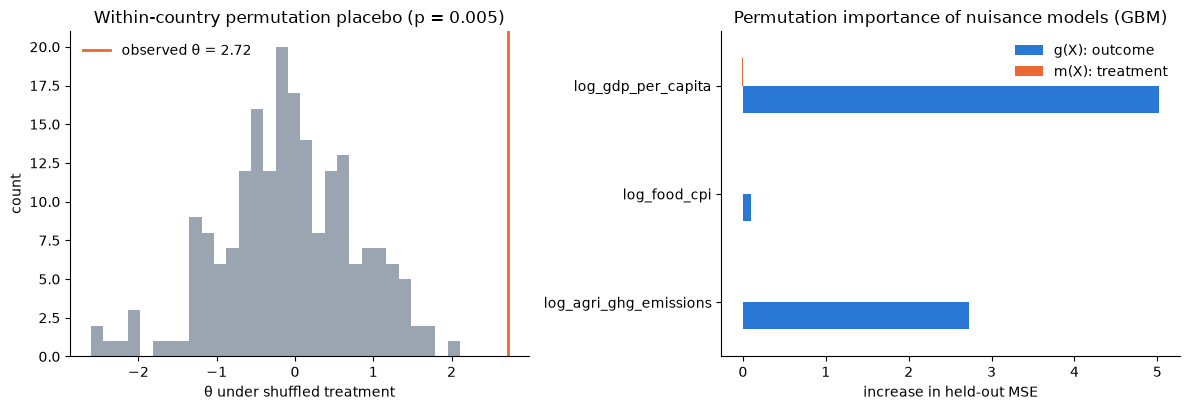

In [17]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(null, bins=30, color="#9aa5b1")
axes[0].axvline(theta_obs, color=ORANGE, lw=2, label=f"observed θ = {theta_obs:.2f}")
axes[0].set(title=f"Within-country permutation placebo (p = {p_perm:.3f})",
            xlabel="θ under shuffled treatment", ylabel="count")
axes[0].legend(frameon=False)
piv = imp.pivot(index="feature", columns="nuisance", values="mse_increase")
piv.plot.barh(ax=axes[1], color=[BLUE, ORANGE])
axes[1].set(title="Permutation importance of nuisance models (GBM)",
            xlabel="increase in held-out MSE", ylabel="")
axes[1].legend(frameon=False)
for a in axes:
    for sp_ in ("top", "right"):
        a.spines[sp_].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "dml_validation.png", dpi=150)
plt.show()

**Reading.** GDP and emissions predict swept obesity, but no control predicts swept subsidies out of sample (importances ≤ 0). The adjustment therefore works almost entirely through the outcome equation, which is why DML and linear FE are close.

## 4. Robustness

Linear two-way FE is used where many refits are needed.

In [18]:
def fe(w, d_cols, y=Y):
    """OLS on swept data; returns the fit with country-clustered SEs."""
    exog = w[d_cols + X]
    groups = pd.factorize(w["country_code"])[0]
    return sm.OLS(w[y], exog).fit(cov_type="cluster", cov_kwds={"groups": groups})


def robustness_value(t, dof, q=1.0):
    """Cinelli & Hazlett RV_q: confounder strength (partial R2 with both D and Y)
    needed to reduce the estimate by 100*q percent."""
    f = q * abs(t) / np.sqrt(dof)
    return 0.5 * (np.sqrt(f ** 4 + 4 * f ** 2) - f ** 2), t ** 2 / (t ** 2 + dof)

### 4.1 Wild cluster bootstrap-t (restricted, Webb weights) — reliable with 13 clusters

In [19]:
def wild_cluster_bootstrap(w, d, rng):
    """Restricted wild cluster bootstrap-t for H0: theta = 0 (Webb 6-point weights)."""
    groups = pd.factorize(w["country_code"])[0]
    G = groups.max() + 1
    xs, xd, y = w[X].to_numpy(), w[[d] + X].to_numpy(), w[Y].to_numpy()
    t_obs = fe(w, [d]).tvalues[d]
    restricted = sm.OLS(y, xs).fit()
    fitted0, u0 = restricted.fittedvalues, restricted.resid
    webb = np.array([-np.sqrt(1.5), -1, -np.sqrt(.5), np.sqrt(.5), 1, np.sqrt(1.5)])
    xtx_inv = np.linalg.inv(xd.T @ xd)
    t_star = np.empty(B)
    for b in range(B):
        ystar = fitted0 + u0 * rng.choice(webb, G)[groups]
        beta = xtx_inv @ xd.T @ ystar
        e = ystar - xd @ beta
        meat = sum(np.outer(s, s) for s in
                   (xd[groups == g].T @ e[groups == g] for g in range(G)))
        n, k = xd.shape
        adj = G / (G - 1) * (n - 1) / (n - k)
        t_star[b] = beta[0] / np.sqrt(adj * (xtx_inv @ meat @ xtx_inv)[0, 0])
    return t_obs, np.mean(np.abs(t_star) >= abs(t_obs))


rob = []
main_fit = fe(w_main, [D])
t_obs, p_wcb = wild_cluster_bootstrap(w_main, D, np.random.default_rng(SEED))
rob.append({"analysis": "Main linear FE", "detail": "cluster-robust", "theta": main_fit.params[D],
            "se": main_fit.bse[D], "p": main_fit.pvalues[D]})
rob.append({"analysis": "Main linear FE", "detail": f"wild cluster bootstrap ({B} draws)",
            "theta": main_fit.params[D], "se": np.nan, "p": p_wcb})
print(f"t = {t_obs:.2f}; wild cluster bootstrap p = {p_wcb:.3f}")

t = 1.89; wild cluster bootstrap p = 0.026


### 4.2 Sensitivity to unobserved confounding (Cinelli & Hazlett 2020)

In [20]:
n_fe = base["country_code"].nunique() + base["year"].nunique() - 1
dof = len(w_main) - n_fe - len(X) - 1
t_cls = sm.OLS(w_main[Y], w_main[[D] + X]).fit().tvalues[D] * np.sqrt(dof / (len(w_main) - len(X) - 1))
rv, r2 = robustness_value(t_cls, dof)
rv_sig, _ = robustness_value(t_cls - 1.96 * np.sign(t_cls), dof)
print(f"partial R2 of treatment = {r2:.3f}")
print(f"RV (estimate -> 0)      = {rv:.3f}")
print(f"RV (loses p<0.05)       = {rv_sig:.3f}")

partial R2 of treatment = 0.029
RV (estimate -> 0)      = 0.160
RV (loses p<0.05)       = 0.055


### 4.3 Leave-one-country-out (linear FE and DML)

In [21]:
loco = []
for c in sorted(base["country_code"].unique()):
    s = base[base["country_code"] != c].reset_index(drop=True)
    ws = sweep(s, [Y, D] + X)
    r = fe(ws, [D])
    th_ml, _, se_ml = dml(ws, Y, D, LEARNERS["gbm"], 3, SEED)
    loco.append({"dropped": c, "theta_fe": r.params[D], "se_fe": r.bse[D], "p_fe": r.pvalues[D],
                 "theta_dml": th_ml, "se_dml": se_ml, "p_dml": p_value(th_ml, se_ml)})
loco = pd.DataFrame(loco)
loco.to_csv(OUT / "robustness_leave_one_out.csv", index=False)
loco

,dropped,theta_fe,se_fe,p_fe,theta_dml,se_dml,p_dml
0,AUS,1.797,0.977,0.066,2.121,1.050,0.043
1,CAN,2.111,1.171,0.071,2.446,1.031,0.018
2,CHE,2.171,1.207,0.072,2.847,1.025,0.005
3,CHL,1.398,0.438,0.001,2.587,0.793,0.001
4,ISL,2.067,1.097,0.059,2.260,1.147,0.049
5,ISR,2.605,1.376,0.058,3.646,1.990,0.067
6,JPN,2.068,1.101,0.060,2.828,1.256,0.024
7,KOR,1.558,1.222,0.202,1.103,0.497,0.027
8,MEX,2.099,1.162,0.071,2.699,0.954,0.005
9,NOR,2.127,1.117,0.057,2.576,0.891,0.004


### 4.4 Lead/lag profile (lags rebuilt from the in-sample PSE series)

In [22]:
prof = []
for k in range(-4, 9):
    col = f"sub_k{k}"
    df[col] = df.groupby("country_code")["log_ag_subsidy_pse"].shift(k)
    s = analysis_sample(df).dropna(subset=[col]).reset_index(drop=True)
    r = fe(sweep(s, [Y, col] + X), [col])
    prof.append({"k": k, "theta": r.params[col], "se": r.bse[col], "p": r.pvalues[col], "N": len(s)})
prof = pd.DataFrame(prof)
prof.to_csv(OUT / "robustness_lag_profile.csv", index=False)
prof

,k,theta,se,p,N
0,-4,-0.868,0.806,0.282,286
1,-3,-0.447,0.794,0.573,298
2,-2,-0.049,0.993,0.961,309
3,-1,0.549,0.969,0.571,317
4,0,0.242,0.821,0.768,325
5,1,0.885,0.666,0.184,312
6,2,1.163,0.906,0.200,299
7,3,1.125,1.214,0.354,286
8,4,0.934,0.899,0.299,273
9,5,0.755,0.702,0.282,260


**Key diagnostic.** The in-sample lag-4 estimate is much smaller than the main one. The values are identical where both exist, so the gap comes from the 52 rows (each country's first 4 years) whose lag uses pre-panel subsidy data.

In [23]:
early = df.groupby("country_code")["log_ag_subsidy_pse"].shift(4).isna()
s_all = analysis_sample(df)
s_late = analysis_sample(df[~early])
for name, s in [("all rows", s_all), ("without first 4 years per country", s_late)]:
    r = fe(sweep(s, [Y, D] + X), [D])
    print(f"{name:36s} N={len(s):3d}  theta={r.params[D]:.3f}  p={r.pvalues[D]:.3f}")

all rows                             N=325  theta=2.029  p=0.059
without first 4 years per country    N=273  theta=0.934  p=0.299


### 4.5 Non-linearity and heterogeneity

In [24]:
b2 = base.copy()
b2["d_c"] = b2[D] - b2[D].mean()
b2["d_sq"] = b2["d_c"] ** 2
r = fe(sweep(b2, [Y, "d_c", "d_sq"] + X), ["d_c", "d_sq"])
rob.append({"analysis": "Quadratic", "detail": "linear term (at mean subsidy)",
            "theta": r.params["d_c"], "se": r.bse["d_c"], "p": r.pvalues["d_c"]})
rob.append({"analysis": "Quadratic", "detail": "squared term",
            "theta": r.params["d_sq"], "se": r.bse["d_sq"], "p": r.pvalues["d_sq"]})

means = base.groupby("country_code")[["log_ag_subsidy_pse", "log_gdp_per_capita"]].mean()
for trait, label in [("log_ag_subsidy_pse", "high-subsidy"), ("log_gdp_per_capita", "high-income")]:
    hi = means.index[means[trait] > means[trait].median()]
    b3 = base.copy()
    b3["d_x_hi"] = b3[D] * b3["country_code"].isin(hi)
    r = fe(sweep(b3, [Y, D, "d_x_hi"] + X), [D, "d_x_hi"])
    rob.append({"analysis": f"Heterogeneity: {label}", "detail": f"effect in other countries ({label} = {', '.join(hi)})",
                "theta": r.params[D], "se": r.bse[D], "p": r.pvalues[D]})
    rob.append({"analysis": f"Heterogeneity: {label}", "detail": f"difference for {label}",
                "theta": r.params["d_x_hi"], "se": r.bse["d_x_hi"], "p": r.pvalues["d_x_hi"]})

robust = pd.DataFrame(rob)
robust.to_csv(OUT / "robustness_summary.csv", index=False)
robust

,analysis,detail,theta,se,p
0,Main linear FE,cluster-robust,2.029,1.073,0.059
1,Main linear FE,wild cluster bootstrap (9999 draws),2.029,NaN,0.026
2,Quadratic,linear term (at mean subsidy),2.837,1.553,0.068
3,Quadratic,squared term,0.325,0.270,0.230
4,Heterogeneity: high-subsidy,"effect in other countries (high-subsidy = CHL, JPN, KOR, MEX, TUR, USA)",1.142,0.584,0.051
5,Heterogeneity: high-subsidy,difference for high-subsidy,2.419,2.219,0.276
6,Heterogeneity: high-income,"effect in other countries (high-income = AUS, CAN, CHE, ISL, NOR, USA)",2.089,1.457,0.152
7,Heterogeneity: high-income,difference for high-income,-0.246,2.095,0.906


**Figure 2.** Lead/lag profile and leave-one-country-out estimates (95% clustered CIs).

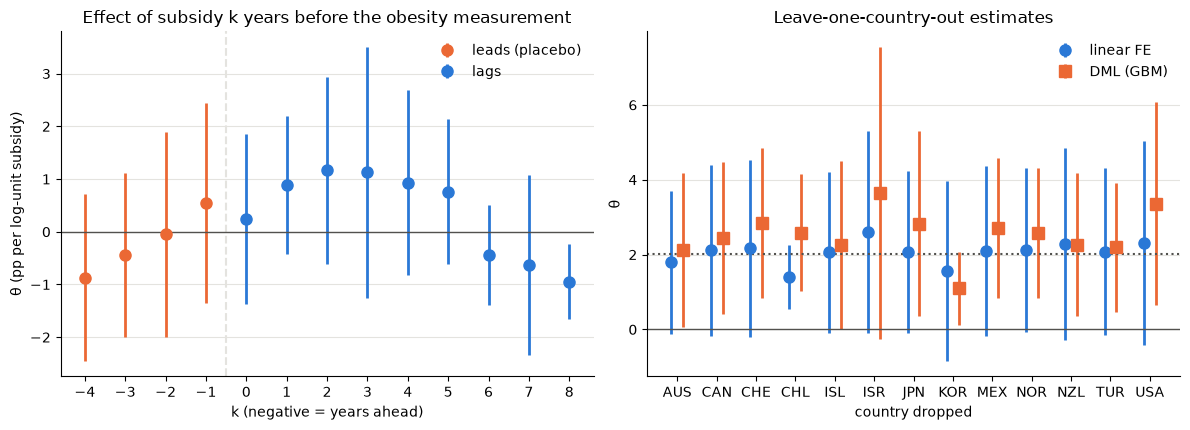

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
lead = prof["k"] < 0
for mask, color, label in [(lead, ORANGE, "leads (placebo)"), (~lead, BLUE, "lags")]:
    p_ = prof[mask]
    ax.errorbar(p_["k"], p_["theta"], yerr=1.96 * p_["se"], fmt="o", ms=8, color=color,
                elinewidth=2, capsize=0, label=label)
ax.axvline(-0.5, color=GRID, ls="--")
ax.set(title="Effect of subsidy k years before the obesity measurement",
       xlabel="k (negative = years ahead)", ylabel="θ (pp per log-unit subsidy)")
ax.set_xticks(prof["k"])
ax.legend(frameon=False)

ax = axes[1]
xs = np.arange(len(loco))
ax.errorbar(xs - 0.15, loco["theta_fe"], yerr=1.96 * loco["se_fe"], fmt="o", ms=8,
            color=BLUE, elinewidth=2, capsize=0, label="linear FE")
ax.errorbar(xs + 0.15, loco["theta_dml"], yerr=1.96 * loco["se_dml"], fmt="s", ms=8,
            color=ORANGE, elinewidth=2, capsize=0, label="DML (GBM)")
ax.axhline(main_fit.params[D], color=MUTED, ls=":")
ax.set_xticks(xs, loco["dropped"])
ax.set(title="Leave-one-country-out estimates", xlabel="country dropped", ylabel="θ")
ax.legend(frameon=False)
for a in axes:
    a.axhline(0, color=MUTED, lw=1)
    a.grid(axis="y", color=GRID)
    a.set_axisbelow(True)
    for sp_ in ("top", "right"):
        a.spines[sp_].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "robustness.png", dpi=150)
plt.show()

## 5. Conclusions

* **Direction is consistent:** every estimator, learner and sample gives a positive effect; the preferred DML estimate implies ≈ +0.27 pp obesity per 10 % rise in subsidies four years earlier.
* **Falsification passes:** future subsidies and a random-walk outcome show no effect; no single country drives the sign; the wild cluster bootstrap keeps the linear estimate significant at 5 %.
* **But it is fragile:** the 52 earliest observations (whose lag uses pre-panel PSE data) carry over half the estimate, no individual in-sample lag is significant, and a confounder explaining ~5.5 % of residual variation in both subsidies and obesity would remove significance.

**Interpretation:** suggestive, not conclusive, evidence. Next steps: verify the pre-panel PSE values, add time-varying controls (education, urbanisation, health spending), and use commodity-level PSE.

*All outputs are written to `results/`.*